In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels

print("Python environment is ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)


Python environment is ready!
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1


In [4]:
import pandas as pd

df = pd.read_csv("UCI_Dataset.csv")

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df.shape

(1067371, 8)

In [6]:
df.info

<bound method DataFrame.info of         Invoice StockCode                          Description  Quantity  \
0        489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1        489434    79323P                   PINK CHERRY LIGHTS        12   
2        489434    79323W                  WHITE CHERRY LIGHTS        12   
3        489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4        489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   
...         ...       ...                                  ...       ...   
1067366  581587     22899         CHILDREN'S APRON DOLLY GIRL          6   
1067367  581587     23254        CHILDRENS CUTLERY DOLLY GIRL          4   
1067368  581587     23255      CHILDRENS CUTLERY CIRCUS PARADE         4   
1067369  581587     22138        BAKING SET 9 PIECE RETROSPOT          3   
1067370  581587      POST                              POSTAGE         1   

                 InvoiceDate  Price  Customer ID       

In [7]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [8]:
print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nQuantity summary:")
print(df["Quantity"].describe())

print("\nPrice summary:")
print(df["Price"].describe())




Dataset shape: (1067371, 8)

Column data types:
Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object

Duplicate rows: 34335

Quantity summary:
count    1.067371e+06
mean     9.938898e+00
std      1.727058e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64

Price summary:
count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64


In [9]:

# Keep the original data safe
df_raw = df.copy()

# 1. Remove exact duplicate rows
df = df.drop_duplicates().copy()

# 2. Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# 3. Remove cancelled invoices
df = df[
    ~df["Invoice"].astype(str).str.startswith("C")
].copy()

# 4. Remove non-positive quantities and prices
df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

# 5. Calculate revenue
df["Revenue"] = df["Quantity"] * df["Price"]

print("Original rows:", len(df_raw))
print("Rows after cleaning:", len(df))
print("Rows removed:", len(df_raw) - len(df))
print("Missing Customer IDs:", df["Customer ID"].isnull().sum())
print("Total revenue:", round(df["Revenue"].sum(), 2))

df.head()


Original rows: 1067371
Rows after cleaning: 1007913
Rows removed: 59458
Missing Customer IDs: 228488
Total revenue: 20476260.45


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [10]:

# Create a separate dataset for customer segmentation
df_customers = df.dropna(subset=["Customer ID"]).copy()

# Convert Customer ID to integer
df_customers["Customer ID"] = (
    df_customers["Customer ID"].astype(int)
)

print("Sales dataset rows:", len(df))
print("Customer segmentation rows:", len(df_customers))
print(
    "Missing Customer IDs:",
    df_customers["Customer ID"].isnull().sum()
)
print(
    "Unique customers:",
    df_customers["Customer ID"].nunique()
)


Sales dataset rows: 1007913
Customer segmentation rows: 779425
Missing Customer IDs: 0
Unique customers: 5878


In [12]:

import pandas as pd

# Define the reference date
snapshot_date = df_customers["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate Recency, Frequency and Monetary value
rfm = df_customers.groupby("Customer ID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM table shape:", rfm.shape)
rfm.head()



RFM table shape: (5878, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346,326,12,77556.46
1,12347,2,8,4921.53
2,12348,75,5,2019.40
3,12349,19,4,4428.69
4,12350,310,1,334.40


In [13]:

import numpy as np
from sklearn.preprocessing import StandardScaler

# Select the three RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce right-skewness
rfm_log = np.log1p(rfm_features)

# Standardize the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

print("Original RFM shape:", rfm_features.shape)
print("Scaled RFM shape:", rfm_scaled.shape)
print("\nFirst 5 scaled rows:")
print(rfm_scaled[:5])


Original RFM shape: (5878, 3)
Scaled RFM shape: (5878, 3)

First 5 scaled rows:
[[ 0.85670058  1.25449595  3.20621937]
 [-2.15197903  0.80016603  1.21599349]
 [-0.07913835  0.29920733  0.57318471]
 [-0.93530818  0.07394609  1.13984551]
 [ 0.82452706 -1.05814595 -0.72302406]]


C:\Users\alenc\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\alenc\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\alenc\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\alenc\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038

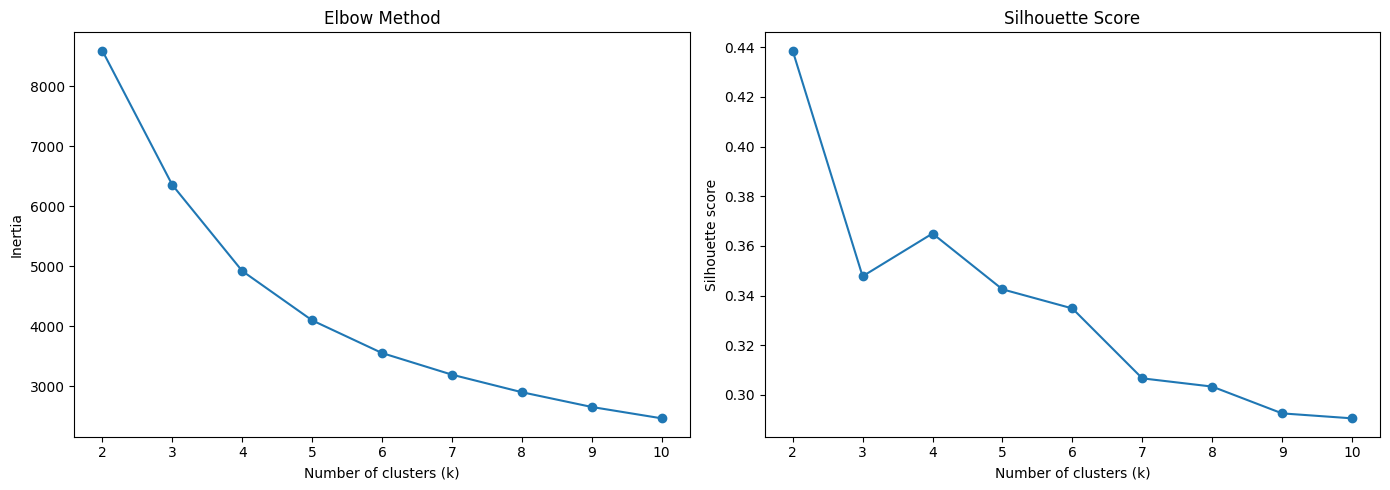

Silhouette scores:
k=2: 0.4386
k=3: 0.3477
k=4: 0.3650
k=5: 0.3425
k=6: 0.3348
k=7: 0.3066
k=8: 0.3033
k=9: 0.2925
k=10: 0.2905


In [14]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

# Plot both evaluation methods
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k={k}: {score:.4f}")


In [15]:

from sklearn.cluster import KMeans

# Train the final candidate model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10,
    algorithm="lloyd"
)

# Assign each customer to a cluster
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("Customers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())



Customers in each cluster:
Cluster
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


In [16]:

cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

print(cluster_summary)


         Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Cluster                                                             
0                  1973       394.95           1.38        317.08   
1                  1250        28.30           3.05        857.49   
2                  1196        27.71          19.28      10731.16   
3                  1459       230.07           5.06       1948.50   

         Total_Revenue  
Cluster                 
0            625601.80  
1           1071864.29  
2          12834470.94  
3           2842867.24  


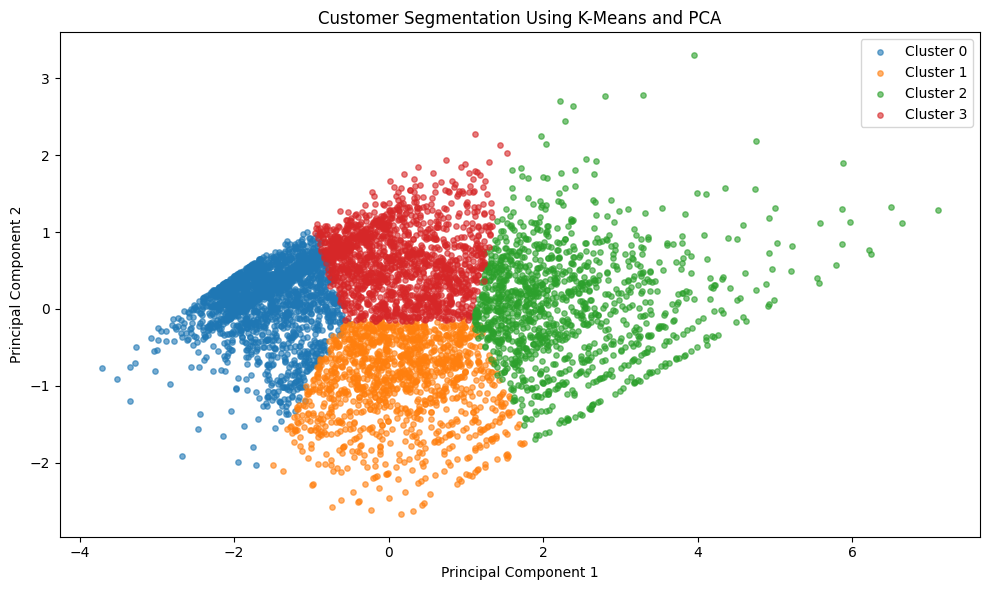

Variance explained: 95.1 %


In [18]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Convert 3 RFM features into 2 dimensions for visualization
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)

# Create the scatter plot
plt.figure(figsize=(10, 6))

for cluster in sorted(rfm["Cluster"].unique()):
    mask = rfm["Cluster"].to_numpy() == cluster

    plt.scatter(
        rfm_pca[mask, 0],
        rfm_pca[mask, 1],
        label=f"Cluster {cluster}",
        alpha=0.6,
        s=15
    )

plt.title("Customer Segmentation Using K-Means and PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

print(
    "Variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


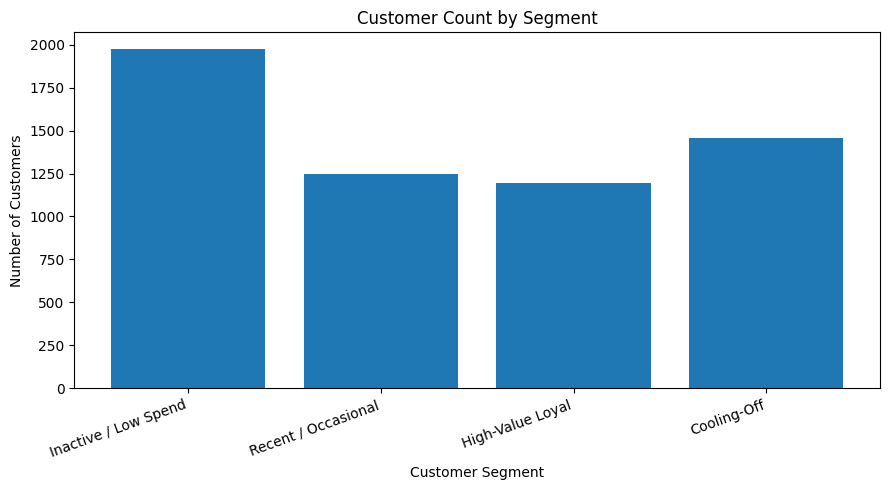

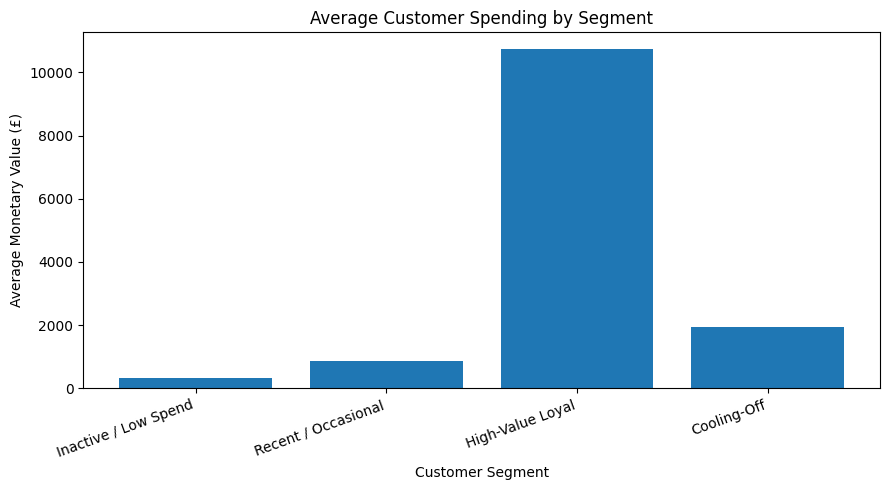

         Customer_Count  Avg_Recency  Avg_Frequency  Avg_Monetary  \
Cluster                                                             
0                  1973       394.95           1.38        317.08   
1                  1250        28.30           3.05        857.49   
2                  1196        27.71          19.28      10731.16   
3                  1459       230.07           5.06       1948.50   

         Total_Revenue               Segment  
Cluster                                       
0            625601.80  Inactive / Low Spend  
1           1071864.29   Recent / Occasional  
2          12834470.94      High-Value Loyal  
3           2842867.24           Cooling-Off  


In [19]:

import matplotlib.pyplot as plt

# Calculate cluster statistics
cluster_summary = rfm.groupby("Cluster").agg(
    Customer_Count=("Customer ID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

segment_names = {
    0: "Inactive / Low Spend",
    1: "Recent / Occasional",
    2: "High-Value Loyal",
    3: "Cooling-Off"
}

cluster_summary["Segment"] = (
    cluster_summary.index.map(segment_names)
)

# Chart 1: Number of customers per segment
plt.figure(figsize=(9, 5))
plt.bar(
    cluster_summary["Segment"],
    cluster_summary["Customer_Count"]
)
plt.title("Customer Count by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Chart 2: Average spending per customer
plt.figure(figsize=(9, 5))
plt.bar(
    cluster_summary["Segment"],
    cluster_summary["Avg_Monetary"]
)
plt.title("Average Customer Spending by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Monetary Value (£)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print(cluster_summary)


First week: 2009-12-06 00:00:00
Last week: 2011-12-11 00:00:00
Number of weeks: 106

Weekly sales summary:
count       106.000000
mean     193172.268377
std       81075.080108
min           0.000000
25%      145566.592500
50%      170865.640000
75%      219896.400000
max      503785.750000
Name: Revenue, dtype: float64


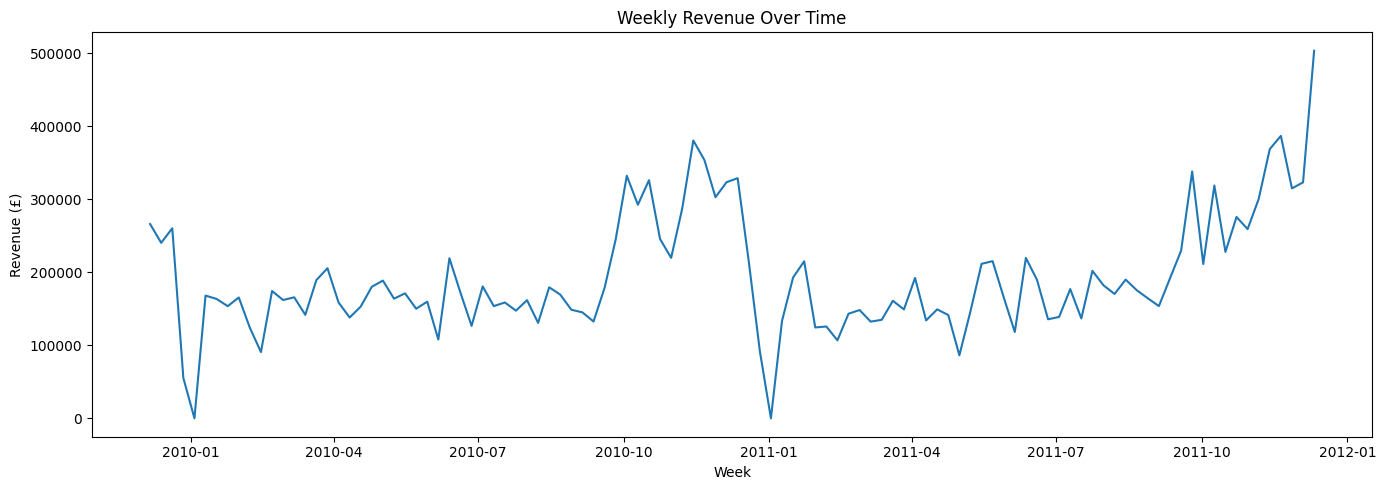

In [20]:

import pandas as pd
import matplotlib.pyplot as plt

# Aggregate transaction revenue into weekly sales
weekly_sales = (
    df.set_index("InvoiceDate")["Revenue"]
      .resample("W")
      .sum()
)

# Fill weeks without recorded sales with zero
weekly_sales = weekly_sales.asfreq("W-SUN", fill_value=0)

print("First week:", weekly_sales.index.min())
print("Last week:", weekly_sales.index.max())
print("Number of weeks:", len(weekly_sales))
print("\nWeekly sales summary:")
print(weekly_sales.describe())

# Plot weekly revenue
plt.figure(figsize=(14, 5))
plt.plot(weekly_sales.index, weekly_sales.values)
plt.title("Weekly Revenue Over Time")
plt.xlabel("Week")
plt.ylabel("Revenue (£)")
plt.tight_layout()
plt.show()


Training weeks: 84
Testing weeks: 22
Training ends: 2011-07-10 00:00:00
Testing starts: 2011-07-17 00:00:00


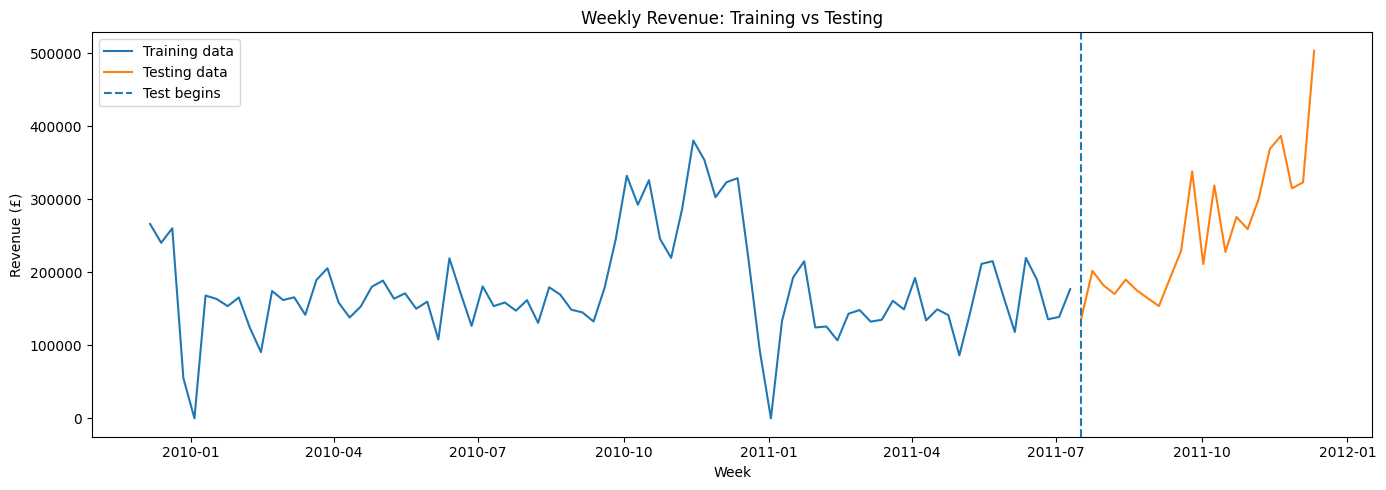

In [21]:

# Chronological 80/20 train-test split
split_point = int(len(weekly_sales) * 0.8)

train = weekly_sales.iloc[:split_point]
test = weekly_sales.iloc[split_point:]

print("Training weeks:", len(train))
print("Testing weeks:", len(test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())

# Plot the split
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Testing data")
plt.axvline(test.index[0], linestyle="--", label="Test begins")
plt.title("Weekly Revenue: Training vs Testing")
plt.xlabel("Week")
plt.ylabel("Revenue (£)")
plt.legend()
plt.tight_layout()
plt.show()


In [22]:

import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline 1: Last training value
naive_pred = np.repeat(train.iloc[-1], len(test))

# Baseline 2: Seasonal naive, using the previous year's value
seasonal_pred = np.array([
    weekly_sales.iloc[split_point + i - 52]
    for i in range(len(test))
])

def evaluate_forecast(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    # MAPE is unreliable when actual values are zero
    nonzero = np.asarray(actual) != 0
    mape = (
        np.mean(
            np.abs(
                (np.asarray(actual)[nonzero] -
                 np.asarray(predicted)[nonzero]) /
                np.asarray(actual)[nonzero]
            )
        ) * 100
        if nonzero.any() else np.nan
    )

    return {
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE (%)": round(mape, 2)
    }

baseline_results = pd.DataFrame({
    "Naive": evaluate_forecast(test, naive_pred),
    "Seasonal Naive": evaluate_forecast(test, seasonal_pred)
}).T

print(baseline_results)


                     MAE       RMSE  MAPE (%)
Naive           86371.20  119806.77     27.68
Seasonal Naive  42744.39   60357.25     16.88


C:\Users\alenc\AppData\Local\Programs\Python\Python313\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


SARIMA results:
{'MAE': 39954.43, 'RMSE': np.float64(58881.24), 'MAPE (%)': np.float64(15.71)}


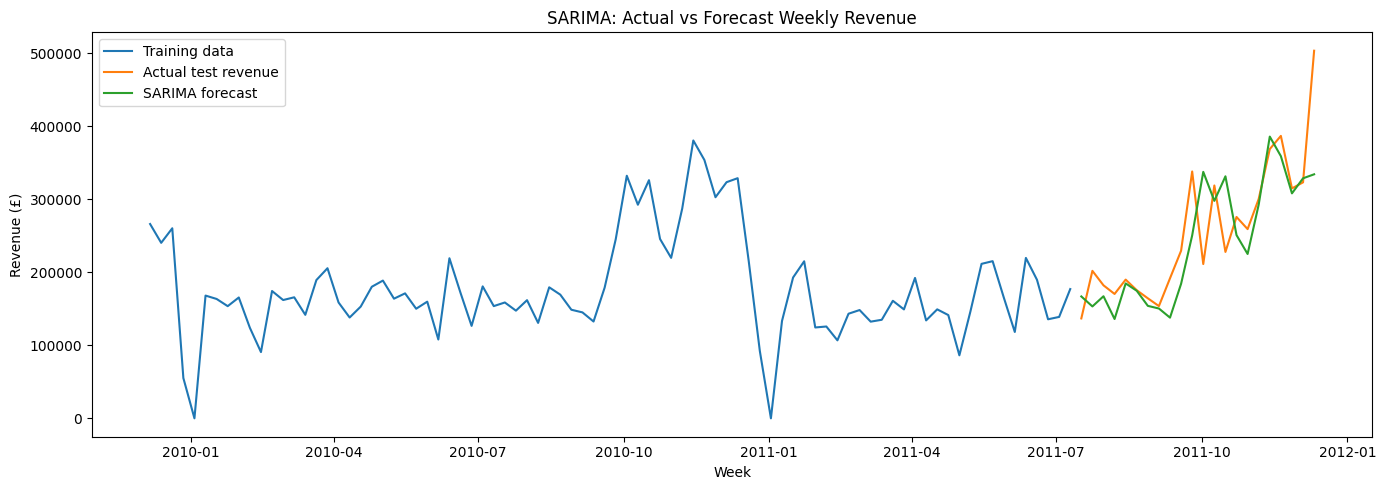

In [23]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Fit a simple seasonal ARIMA model
sarima_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = sarima_model.fit(disp=False, maxiter=200)

# Forecast the test period
sarima_forecast = sarima_fit.get_forecast(
    steps=len(test)
)

sarima_pred = sarima_forecast.predicted_mean
sarima_pred.index = test.index

# Evaluate the forecast
sarima_results = evaluate_forecast(test, sarima_pred)

print("SARIMA results:")
print(sarima_results)

# Plot actual vs predicted revenue
plt.figure(figsize=(14, 5))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test revenue")
plt.plot(test.index, sarima_pred, label="SARIMA forecast")
plt.title("SARIMA: Actual vs Forecast Weekly Revenue")
plt.xlabel("Week")
plt.ylabel("Revenue (£)")
plt.legend()
plt.tight_layout()
plt.show()


Holt-Winters results:
{'MAE': 132673.73, 'RMSE': np.float64(173089.36), 'MAPE (%)': np.float64(43.74)}


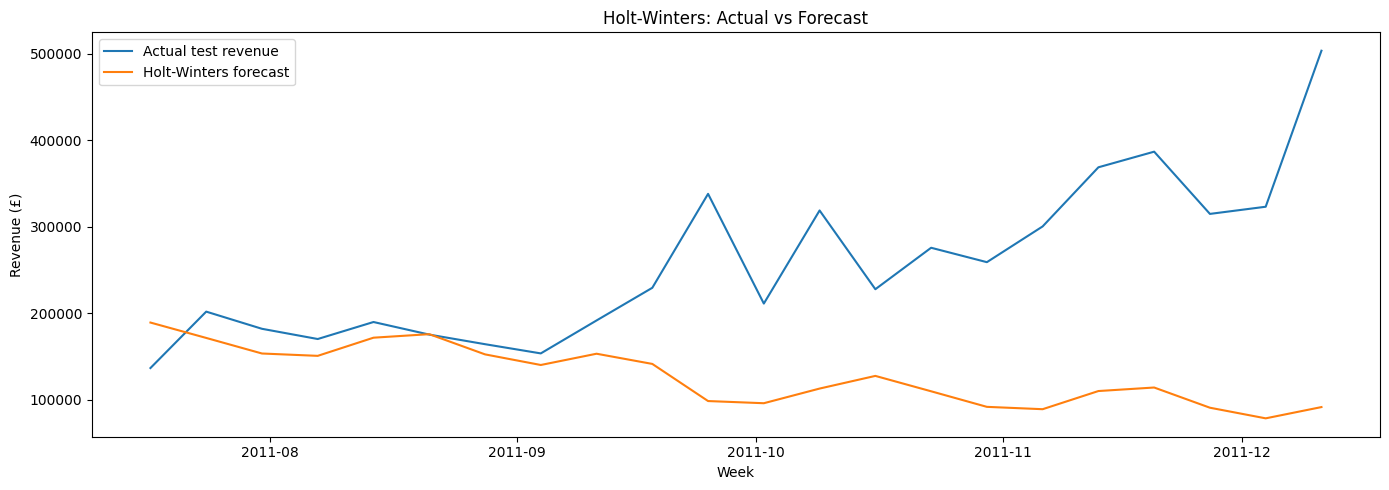

In [25]:

from statsmodels.tsa.holtwinters import ExponentialSmoothing
import matplotlib.pyplot as plt

# Use a 13-week seasonal period because the training
# dataset is too short for a 52-week seasonal period
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=13,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)

# Forecast the test period
hw_pred = hw_fit.forecast(len(test))
hw_pred.index = test.index

# Evaluate the forecast
hw_results = evaluate_forecast(test, hw_pred)

print("Holt-Winters results:")
print(hw_results)

# Plot actual versus forecast
plt.figure(figsize=(14, 5))
plt.plot(test.index, test, label="Actual test revenue")
plt.plot(test.index, hw_pred, label="Holt-Winters forecast")
plt.title("Holt-Winters: Actual vs Forecast")
plt.xlabel("Week")
plt.ylabel("Revenue (£)")
plt.legend()
plt.tight_layout()
plt.show()


Next 8 weeks forecast:
2011-12-18    457919.14
2011-12-25    412957.74
2012-01-01    397273.53
2012-01-08    419196.62
2012-01-15    407536.85
2012-01-22    429422.94
2012-01-29    395213.56
2012-02-05    410211.89
Freq: W-SUN, Name: predicted_mean, dtype: float64


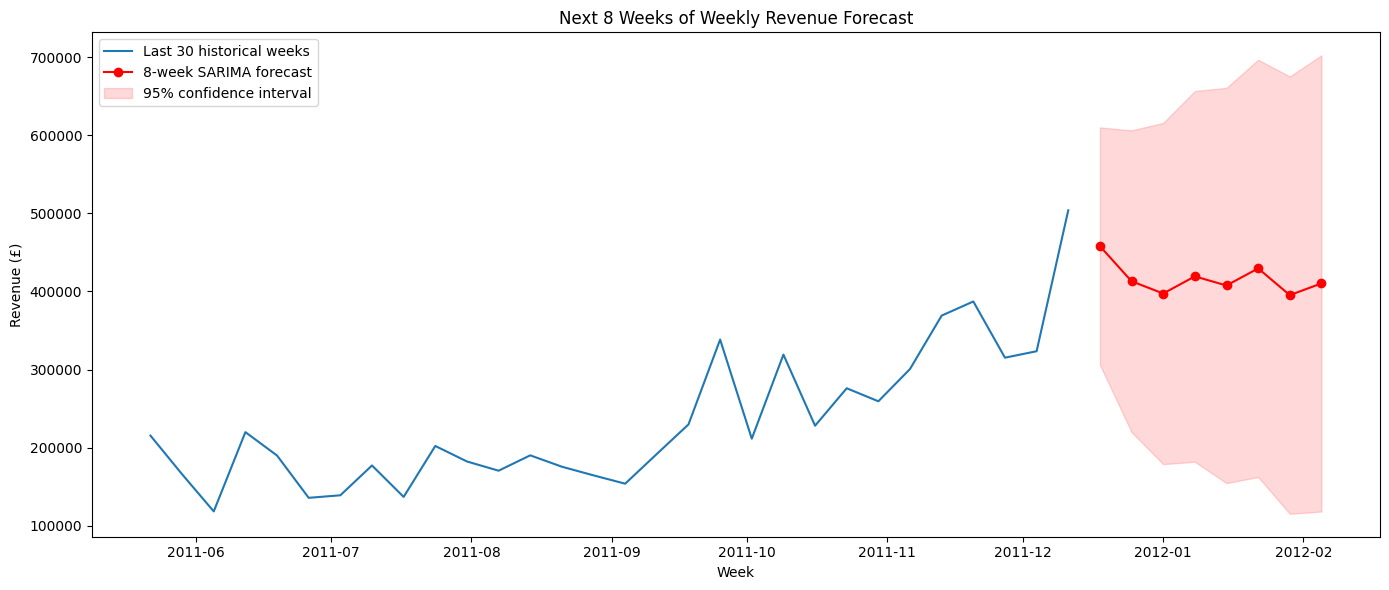

In [27]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
import pandas as pd

# Fit SARIMA on all available historical data
final_model = SARIMAX(
    weekly_sales,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 13),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# Forecast the next 8 weeks
final_forecast = final_model.get_forecast(steps=8)

forecast_values = final_forecast.predicted_mean
confidence_intervals = final_forecast.conf_int()

print("Next 8 weeks forecast:")
print(forecast_values.round(2))

# Plot historical data and future forecast
plt.figure(figsize=(14, 6))
plt.plot(
    weekly_sales.index[-30:],
    weekly_sales.iloc[-30:],
    label="Last 30 historical weeks"
)
plt.plot(
    forecast_values.index,
    forecast_values,
    color="red",
    marker="o",
    label="8-week SARIMA forecast"
)
plt.fill_between(
    forecast_values.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    color="red",
    alpha=0.15,
    label="95% confidence interval"
)

plt.title("Next 8 Weeks of Weekly Revenue Forecast")
plt.xlabel("Week")
plt.ylabel("Revenue (£)")
plt.legend()
plt.tight_layout()
plt.show()


In [28]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Fit the current model on training data only
validation_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 13),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

# Forecast the held-out test period
validation_forecast = validation_model.get_forecast(
    steps=len(test)
).predicted_mean

validation_forecast.index = test.index

# Calculate error metrics
mae = mean_absolute_error(test, validation_forecast)
rmse = np.sqrt(mean_squared_error(test, validation_forecast))

# MAPE can be misleading when actual values are zero
nonzero = test != 0
mape = (
    np.mean(
        np.abs(
            (test[nonzero] - validation_forecast[nonzero])
            / test[nonzero]
        )
    ) * 100
)

print("Validation results for the current SARIMA model")
print(f"MAE:  £{mae:,.2f}")
print(f"RMSE: £{rmse:,.2f}")
print(f"MAPE: {mape:.2f}%")


Validation results for the current SARIMA model
MAE:  £88,571.65
RMSE: £117,653.60
MAPE: 29.62%


In [29]:

import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "Original SARIMA",
        "Holt-Winters",
        "SARIMA (13-week season)"
    ],
    "MAE (£)": [
        86371.20,
        42744.39,
        39954.43,
        132673.73,
        88571.65
    ],
    "RMSE (£)": [
        119806.77,
        60357.25,
        58881.24,
        173089.36,
        117653.60
    ],
    "MAPE (%)": [
        27.68,
        16.88,
        15.71,
        43.74,
        None
    ]
})

comparison = comparison.sort_values("RMSE (£)")

print(comparison.to_string(index=False))


                  Model   MAE (£)  RMSE (£)  MAPE (%)
        Original SARIMA  39954.43  58881.24     15.71
         Seasonal Naive  42744.39  60357.25     16.88
SARIMA (13-week season)  88571.65 117653.60       NaN
                  Naive  86371.20 119806.77     27.68
           Holt-Winters 132673.73 173089.36     43.74


In [30]:

# Final project summary

summary = """
ONLINE RETAIL ANALYTICS PROJECT
Customer Segmentation and Weekly Sales Forecasting

DATASET
Online Retail II dataset.
Customer segmentation: 5,878 customers.
Weekly forecasting: 106 weeks.
Forecast evaluation: 84 training weeks and 22 testing weeks.

CUSTOMER SEGMENTATION
Method: RFM analysis, StandardScaler, K-Means, and PCA visualization.
Number of clusters: 4.

Segment findings:
1. Inactive / Low Spend: 1,973 customers.
2. Recent / Occasional: 1,250 customers.
3. High-Value Loyal: 1,196 customers.
4. Cooling-Off: 1,459 customers.

FORECASTING
Frequency: Weekly revenue.
Best tested model: Original SARIMA.
Forecast horizon: 8 weeks.

Original SARIMA test results:
MAE: £39,954.43
RMSE: £58,881.24
MAPE: 15.71%

Seasonal Naive baseline:
MAE: £42,744.39
RMSE: £60,357.25
MAPE: 16.88%

Holt-Winters:
MAE: £132,673.73
RMSE: £173,089.36
MAPE: 43.74%

CONCLUSION
The original SARIMA model outperformed the tested baselines
on the reported error metrics, with a modest improvement over
the seasonal-naive baseline. Further tuning and validation
would be needed before operational deployment.
"""

with open("project_summary.txt", "w", encoding="utf-8") as f:
    f.write(summary)

print("Project summary saved as project_summary.txt")


Project summary saved as project_summary.txt
